Classifier: Logistic Regression
F1 Score: 0.8611
Recall: 0.8671
Precision: 0.8552
Accuracy: 0.8837
Confusion Matrix:
[[180  21]
 [ 19 124]]



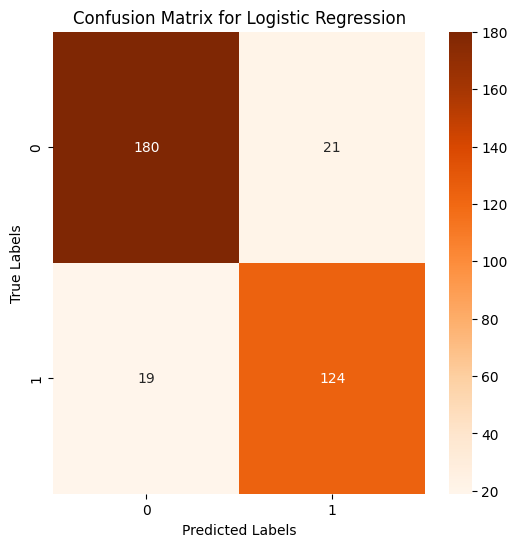

Classifier: Decision Tree
F1 Score: 0.7730
Recall: 0.7622
Precision: 0.7842
Accuracy: 0.8140
Confusion Matrix:
[[171  30]
 [ 34 109]]



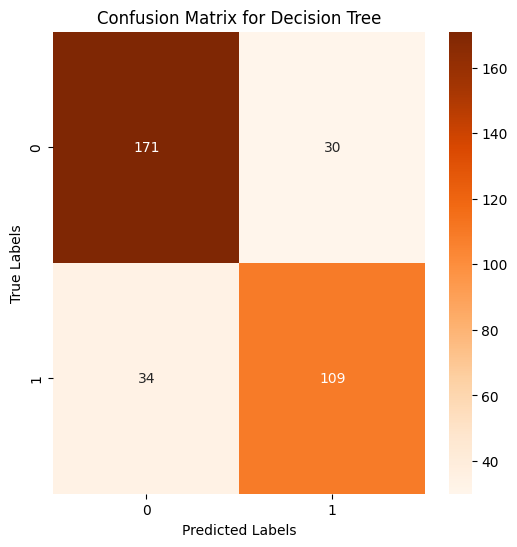

Classifier: Random Forest
F1 Score: 0.8351
Recall: 0.8322
Precision: 0.8380
Accuracy: 0.8634
Confusion Matrix:
[[178  23]
 [ 24 119]]



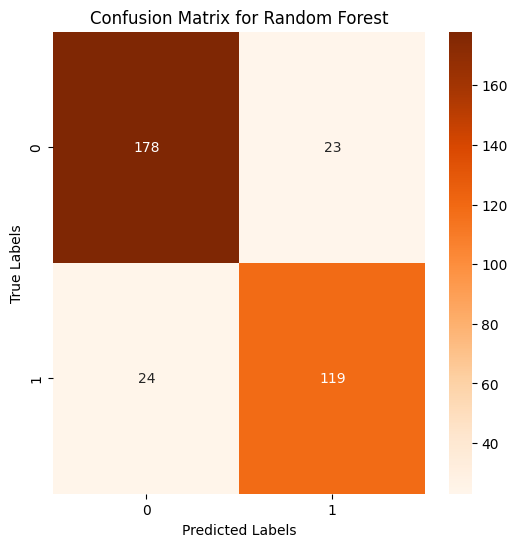

Classifier: Gradient Boosting
F1 Score: 0.8664
Recall: 0.8392
Precision: 0.8955
Accuracy: 0.8924
Confusion Matrix:
[[187  14]
 [ 23 120]]



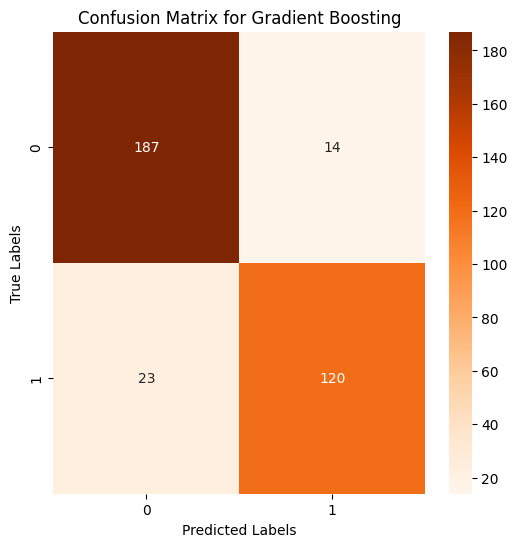

Classifier: Support Vector Machine
F1 Score: 0.8581
Recall: 0.8671
Precision: 0.8493
Accuracy: 0.8808
Confusion Matrix:
[[179  22]
 [ 19 124]]



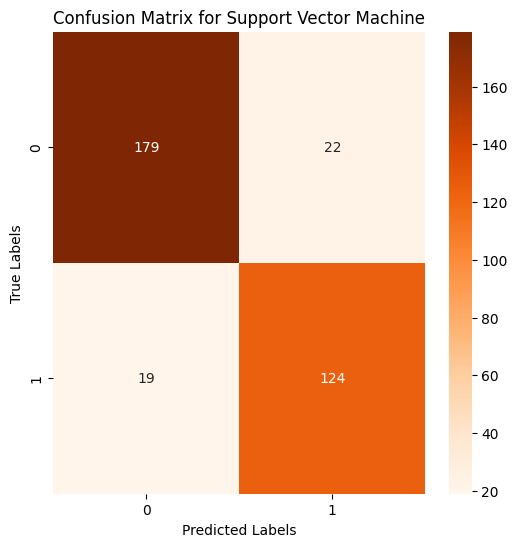

Classifier: K-Nearest Neighbors
F1 Score: 0.8362
Recall: 0.8392
Precision: 0.8333
Accuracy: 0.8634
Confusion Matrix:
[[177  24]
 [ 23 120]]



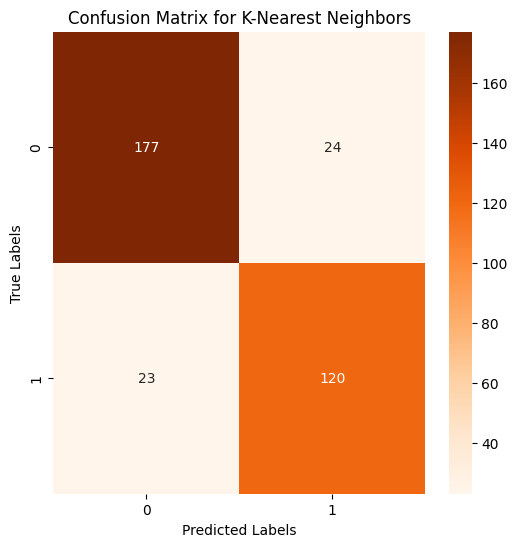

Classifier: Gaussian Naive Bayes
F1 Score: 0.8533
Recall: 0.8951
Precision: 0.8153
Accuracy: 0.8721
Confusion Matrix:
[[172  29]
 [ 15 128]]



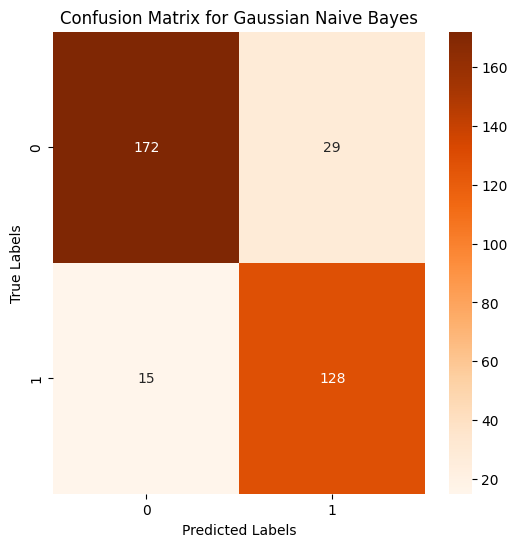

Best Classifier based on Accuracy Score: Gradient Boosting


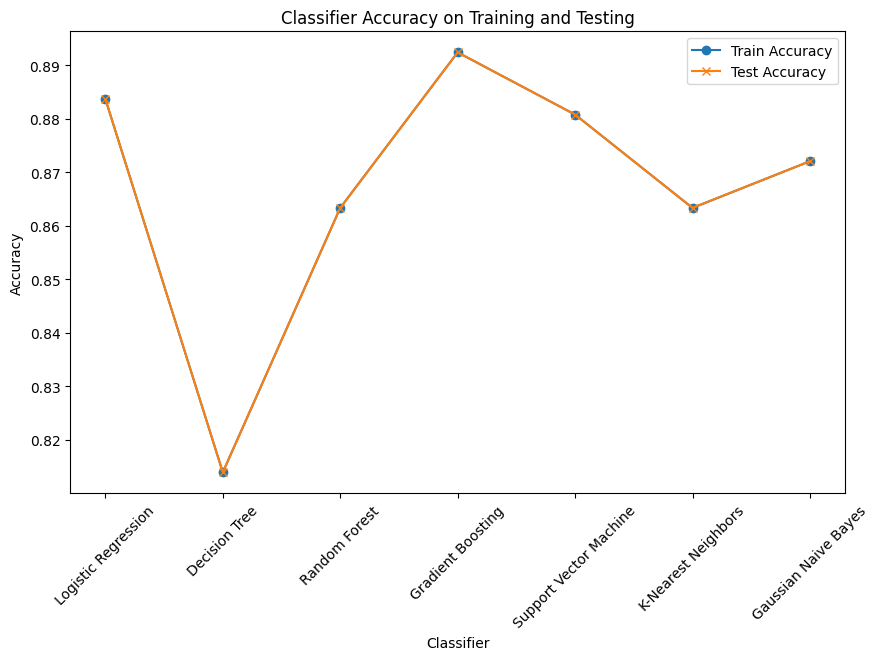

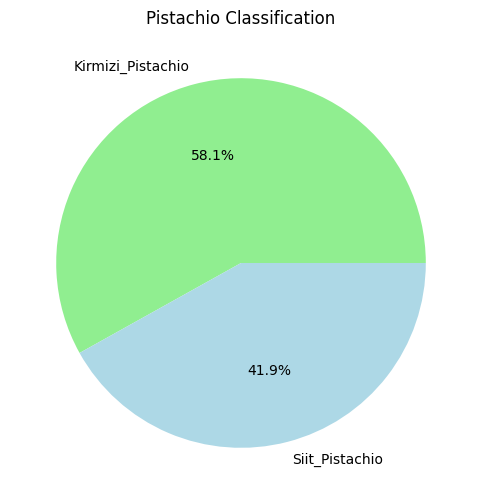

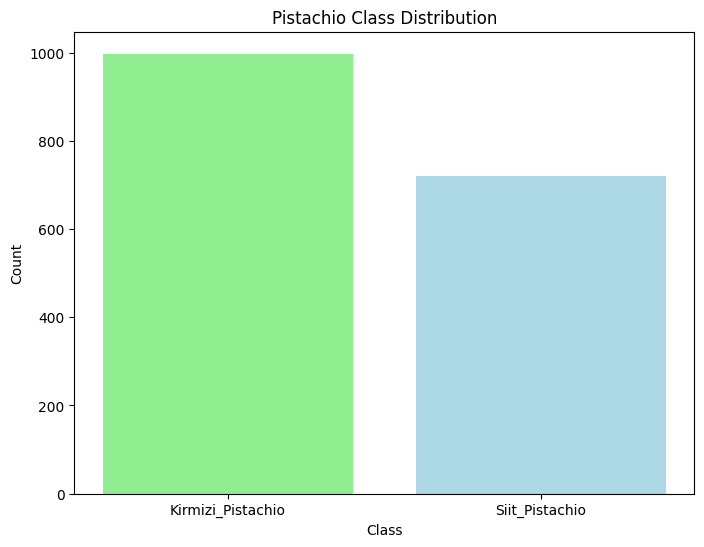

In [23]:
import pandas as pd
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.model_selection import train_test_split
import seaborn as sns

# Load the dataset
data = pd.read_csv('/content/sample_data/pistachio.csv')

# Separate features and target variable
X = data.drop('Class', axis=1)
y = data['Class']

# Standardize the features
scaler = StandardScaler()
X = scaler.fit_transform(X)

# Encode the target variable
label_encoder = LabelEncoder()
y = label_encoder.fit_transform(y)

# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
import matplotlib.pyplot as plt

classifiers = {
    'Logistic Regression': LogisticRegression(),
    'Decision Tree': DecisionTreeClassifier(),
    'Random Forest': RandomForestClassifier(),
    'Gradient Boosting': GradientBoostingClassifier(),
    'Support Vector Machine': SVC(),
    'K-Nearest Neighbors': KNeighborsClassifier(),
    'Gaussian Naive Bayes': GaussianNB()
}

from sklearn.metrics import f1_score, recall_score, precision_score, accuracy_score, confusion_matrix

results = {}
for clf_name, clf in classifiers.items():
    clf.fit(X_train, y_train)
    y_pred = clf.predict(X_test)

    f1 = f1_score(y_test, y_pred)
    recall = recall_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred)
    accuracy = accuracy_score(y_test, y_pred)
    cm = confusion_matrix(y_test, y_pred)

    results[clf_name] = {
        'F1 Score': f1,
        'Recall': recall,
        'Precision': precision,
        'Accuracy': accuracy,
        'Confusion Matrix': cm
    }

for clf_name, scores in results.items():
    print(f'Classifier: {clf_name}')
    print(f'F1 Score: {scores["F1 Score"]:.4f}')
    print(f'Recall: {scores["Recall"]:.4f}')
    print(f'Precision: {scores["Precision"]:.4f}')
    print(f'Accuracy: {scores["Accuracy"]:.4f}')
    print('Confusion Matrix:')
    print(scores['Confusion Matrix'])
    print()


     # Print Confusion Matrix in orange
    plt.figure(figsize=(6, 6))
    sns.heatmap(scores['Confusion Matrix'], annot=True, fmt='d', cmap='Oranges')
    plt.xlabel('Predicted Labels')
    plt.ylabel('True Labels')
    plt.title(f'Confusion Matrix for {clf_name}')
    plt.show()



best_classifier = max(results, key=lambda x: results[x]['Accuracy'])
print(f'Best Classifier based on Accuracy Score: {best_classifier}')


train_scores = [results[clf_name]['Accuracy'] for clf_name in classifiers.keys()]
test_scores = [results[clf_name]['Accuracy'] for clf_name in classifiers.keys()]

plt.figure(figsize=(10, 6))
plt.plot(classifiers.keys(), train_scores, marker='o', label='Train Accuracy')
plt.plot(classifiers.keys(), test_scores, marker='x', label='Test Accuracy')
plt.xlabel('Classifier')
plt.ylabel('Accuracy')
plt.legend()
plt.title('Classifier Accuracy on Training and Testing')
plt.xticks(rotation=45)
plt.show()


best_clf = classifiers[best_classifier]
best_clf.fit(X, y)

# Classify Pistachio into Kirmizi-Pistachio (Class 0) and Siit-Pistachio (Class 1)
pistachio_class = best_clf.predict(X)
pistachio_class = label_encoder.inverse_transform(pistachio_class)

# Draw Pie Chart
plt.figure(figsize=(6, 6))
plt.pie(data['Class'].value_counts(), labels=data['Class'].unique(), autopct='%1.1f%%', colors=['lightgreen', 'lightblue'])
plt.title('Pistachio Classification')
plt.show()

# Draw Bar Graph
plt.figure(figsize=(8, 6))
plt.bar(data['Class'].unique(), data['Class'].value_counts(), color=['lightgreen', 'lightblue'])
plt.xlabel('Class')
plt.ylabel('Count')
plt.title('Pistachio Class Distribution')
plt.show()




